<a href="https://colab.research.google.com/github/lgpsouza/agentx/blob/main/AKCIT_AIA_Colab_Unidade_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

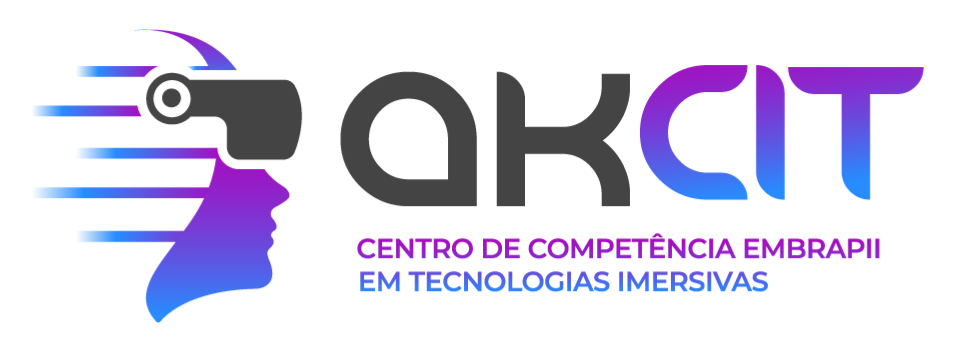


# Identificação

**Microcurso:** Agentes de IA

**Docente:** MsC. Leon Sólon da Silva

# Objetivos de Aprendizagem

- Entender o que e um agente conversacional simples e seu fluxo.
- Construir um prompt parametrizado e chamar um LLM (Gemini).
- Orquestrar etapas com LangGraph (estado, nos e transicoes).
- Rodar um exemplo completo no Colab.

# Estruturacao
1. Instalar bibliotecas.
2. Configurar chave da API.
3. Definir prompt e pipeline (prompt | llm | parser).
4. Criar grafo com boas-vindas, captura de nome e Q&A.
5. Executar exemplos e observar respostas.


# Laboratório 1 - TechAdvisor (Colab)

Nesse notebook vamos criar um agente bem simples, um tech advisor que responder perguntas sobre carreira de tecnologia.

### Dependências
Nesta célula instalamos as bibliotecas que o notebook vai usar.

- baixa os pacotes principais (LLM, orquestracao e ferramentas auxiliares)
- prepara o ambiente do Colab para rodar o restante do codigo
- pode levar alguns segundos na primeira execucao


In [ ]:
!pip -q install langchain langgraph langchain-google-genai google-generativeai

### Credenciais da API
Nesta etapa voce informa a chave do provedor de LLM.

- a chave fica apenas na sessao atual do Colab
- sem isso o modelo nao consegue gerar respostas

Nesse exemplo vamos usar o Gemini! É bem fácil conseguir uma API KEY, [nesse vídeo](https://www.youtube.com/watch?v=Uyn-P2nRvDA) você pode gerar uma pra testar esse notebook.

In [ ]:
import os
import getpass

os.environ['GOOGLE_API_KEY'] = getpass.getpass('GOOGLE_API_KEY: ')

GOOGLE_API_KEY: ··········


### Definicao do agente (LangGraph)
Aqui construimos o agente completo: prompt, modelo e o grafo de estados.

- criamos o prompt parametrizado com nome e pergunta
- conectamos o prompt ao LLM e ao parser de saida
- definimos os nos (boas-vindas, captura de nome e respostas)
- criamos as transicoes que controlam o fluxo da conversa


In [ ]:
import re
from langchain_core.prompts import PromptTemplate
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.output_parsers import StrOutputParser
from langgraph.graph import StateGraph, END

llm = ChatGoogleGenerativeAI(
    model='gemini-2.0-flash',
    temperature=0.6,
)

template_text = (
    'Voce e o TechAdvisor, um assistente amigavel de tecnologia.\n'
    'Fale em portugues, de forma curta e objetiva.\n'
    'Nome do usuario: {nome}\n'
    'Pergunta do usuario: {pergunta}\n'
)
prompt = PromptTemplate(
    input_variables=['nome', 'pergunta'],
    template=template_text
)

qa_chain = prompt | llm | StrOutputParser()

def extrair_nome(texto: str) -> str:
    if not texto:
        return ''
    candidato = texto.strip()
    candidato = candidato.strip(" \"'")
    partes = [p.capitalize() for p in re.split(r'\s+', candidato) if p]
    return ' '.join(partes)

def boas_vindas_node(state: dict) -> dict:
    state['resposta'] = 'Ola! Eu sou o TechAdvisor. Como posso te chamar?'
    state['etapa'] = 'aguardar_nome'
    return state

def aguardar_nome_node(state: dict) -> dict:
    mensagem = (state.get('mensagem_usuario') or '').strip()
    if not mensagem:
        state['resposta'] = 'Nao entendi. Qual e o seu nome?'
        state['etapa'] = 'aguardar_nome'
        return state
    nome = extrair_nome(mensagem)
    if not nome:
        state['resposta'] = 'Pode repetir seu nome, por favor?'
        state['etapa'] = 'aguardar_nome'
        return state
    state['nome'] = nome
    state['resposta'] = f'Prazer, {nome}! Como posso ajudar em tecnologia hoje?'
    state['etapa'] = 'responder_perguntas'
    return state

def responder_perguntas_node(state: dict) -> dict:
    mensagem = (state.get('mensagem_usuario') or '').strip()
    nome = state.get('nome', 'usuario')
    if mensagem.lower() == 'tchau' or 'tchau' in mensagem.lower():
        state['resposta'] = f'Ate logo, {nome}!'
        state['etapa'] = 'fim'
        return state
    resposta = qa_chain.invoke({
        'nome': nome,
        'pergunta': mensagem or 'Dica simples de tecnologia'
    })
    state['resposta'] = resposta
    state['etapa'] = 'responder_perguntas'
    return state

def roteador_node(state: dict) -> dict:
    return state

def proxima_parada(state: dict) -> str:
    etapa = state.get('etapa')
    if etapa == 'aguardar_nome':
        return 'aguardar_nome'
    if etapa == 'responder_perguntas':
        return 'responder_perguntas'
    if etapa == 'fim':
        return 'fim'
    return 'boas_vindas'

graph = StateGraph(dict)
graph.add_node('roteador', roteador_node)
graph.add_node('boas_vindas', boas_vindas_node)
graph.add_node('aguardar_nome', aguardar_nome_node)
graph.add_node('responder_perguntas', responder_perguntas_node)

graph.add_conditional_edges(
    'roteador',
    proxima_parada,
    {
        'boas_vindas': 'boas_vindas',
        'aguardar_nome': 'aguardar_nome',
        'responder_perguntas': 'responder_perguntas',
        'fim': END,
    },
)
graph.add_edge('boas_vindas', END)
graph.add_edge('aguardar_nome', END)
graph.add_edge('responder_perguntas', END)
graph.set_entry_point('roteador')

app = graph.compile()

### Execucao do fluxo
Vamos rodar o grafo passo a passo para simular a conversa.

- iniciamos o estado vazio
- enviamos mensagens de exemplo
- observamos como o agente responde em cada etapa


In [ ]:
import time

state = {}
state.update(app.invoke(state))
print(state.get('resposta', ''))

for msg in ['Ana', 'Quero aprender backend com Python', 'tchau']:
    state['mensagem_usuario'] = msg
    state.update(app.invoke(state))
    print(state.get('resposta', ''))
    time.sleep(1)

Ola! Eu sou o TechAdvisor. Como posso te chamar?
Prazer, Ana! Como posso ajudar em tecnologia hoje?
Olá Ana! Ótima escolha! Para backend com Python, foque em:

1.  **Frameworks:** Django (completo) ou Flask (micro).
2.  **Bancos de dados:** PostgreSQL, MySQL.
3.  **APIs:** Crie APIs RESTful.
4.  **Pratique:** Muitos projetos pequenos!

Bons estudos! Se precisar de mais detalhes, só perguntar!
Ate logo, Ana!


## Próximos passos

Agora tente você! Mude as mensagens de interações com os agentes! Tente alterar o código para pegar input do usuário, por exemplo. O céu é o limite :)